<a href="https://colab.research.google.com/github/Adrentur/-1_-_-_-3-10/blob/main/%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0_%D1%80%D0%BE%D0%B1%D0%BE%D1%82%D0%B0_11_%D0%9F%D0%BE%D0%BB%D1%94%D1%85%D1%96%D0%BD_%D0%84%D0%B3%D0%BE%D1%80_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DATA_DIR, IMG_SIZE, NUM_CLASSES = 'gtsrb_data', 32, 43

classes = {
    0: '20 км/год', 1: '30 км/год', 2: '50 км/год', 3: '60 км/год', 4: '70 км/год',
    5: '80 км/год', 6: 'Кінець 80', 7: '100 км/год', 8: '120 км/год', 9: 'Обгін заборонено',
    10: 'Обгін вантажівкам заборонено', 11: 'Перехрестя з другорядною', 12: 'Головна дорога',
    13: 'Дати дорогу', 14: 'STOP', 15: 'Рух заборонено', 16: 'Вантажівкам заборонено',
    17: 'В’їзд заборонено', 18: 'Інша небезпека', 19: 'Поворот ліворуч', 20: 'Поворот праворуч',
    21: 'Декілька поворотів', 22: 'Нерівна дорога', 23: 'Слизька дорога', 24: 'Звуження справа',
    25: 'Дорожні роботи', 26: 'Світлофор', 27: 'Пішохідний перехід', 28: 'Діти',
    29: 'Велосипедисти', 30: 'Ожеледиця / Сніг', 31: 'Дикі тварини', 32: 'Кінець усіх обмежень',
    33: 'Рух праворуч', 34: 'Рух ліворуч', 35: 'Рух прямо', 36: 'Прямо або праворуч',
    37: 'Прямо або ліворуч', 38: 'Об’їзд справа', 39: 'Об’їзд зліва', 40: 'Круговий рух',
    41: 'Кінець заборони обгону', 42: 'Кінець заборони обгону вантажівкам'
}
print("Device:", device)

Device: cuda


In [2]:
import os

if not os.path.exists('gtsrb_data/Train/0'):
    if not os.path.exists('gtsrb-german-traffic-sign.zip'):
        !mkdir -p ~/.kaggle
        !cp kaggle.json ~/.kaggle/
        !chmod 600 ~/.kaggle/kaggle.json
        !kaggle datasets download -d meowmeowmeowmeowmeow/gtsrb-german-traffic-sign
    !unzip -q -o gtsrb-german-traffic-sign.zip -d gtsrb_data

print("Готово:", os.path.exists('gtsrb_data/Train/0'))

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign
License(s): CC0-1.0
100% 612M/612M [00:03<00:00, 209MB/s]

Готово: True


X: (39209, 32, 32, 3) y: (39209,)


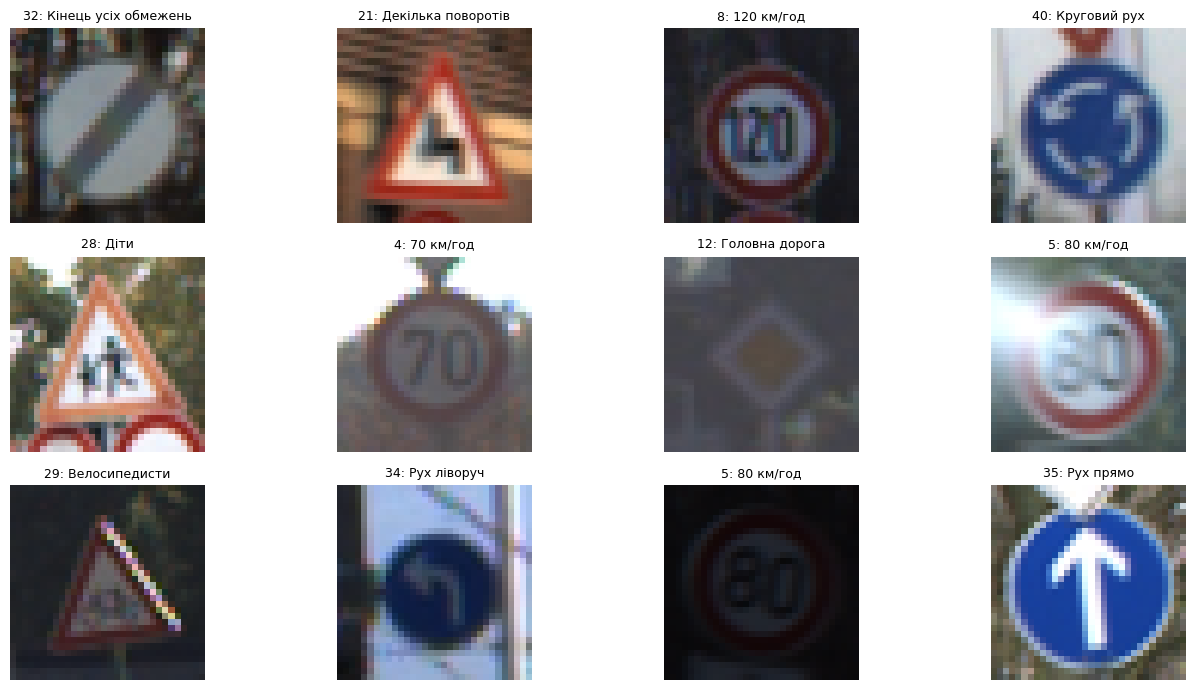

In [3]:
X, y = [], []
for c in range(NUM_CLASSES):
    for f in os.listdir(os.path.join(DATA_DIR, 'Train', str(c))):
        img = Image.open(os.path.join(DATA_DIR, 'Train', str(c), f)).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
        X.append(np.array(img, dtype=np.uint8))
        y.append(c)
X, y = np.array(X), np.array(y)
print("X:", X.shape, "y:", y.shape)

plt.figure(figsize=(14, 7))
for i, idx in enumerate(random.sample(range(len(X)), 12)):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X[idx])
    plt.title(f"{y[idx]}: {classes[y[idx]]}", fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

In [4]:
X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

tr_tf = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.85, 1.15)),
    transforms.ToTensor()
])
va_tf = transforms.Compose([transforms.ToPILImage(), transforms.ToTensor()])

class SignDS(Dataset):
    def __init__(self, imgs, lbls, tf):
        self.imgs, self.lbls, self.tf = imgs, lbls, tf
    def __len__(self): return len(self.imgs)
    def __getitem__(self, i): return self.tf(self.imgs[i]), int(self.lbls[i])

tr_loader = DataLoader(SignDS(X_tr, y_tr, tr_tf), batch_size=64, shuffle=True)
va_loader = DataLoader(SignDS(X_va, y_va, va_tf), batch_size=64)
print("Тренувальна вибірка:", len(X_tr), "| Валідаційна вибірка:", len(X_va))

Тренувальна вибірка: 31367 | Валідаційна вибірка: 7842


In [5]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 32, 3), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2), nn.Dropout2d(0.25),

            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 64, 3), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2), nn.Dropout2d(0.25),

            nn.Flatten(),
            nn.Linear(64 * 6 * 6, 512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(512, NUM_CLASSES)
        )
    def forward(self, x): return self.net(x)

model = CNN().to(device)
opt = optim.Adam(model.parameters(), lr=1e-3)
crit = nn.CrossEntropyLoss()
print("Кількість параметрів:", sum(p.numel() for p in model.parameters()))

Кількість параметрів: 1269195


In [6]:
EPOCHS = 10
tr_acc, va_acc, tr_loss, va_loss = [], [], [], []

for ep in range(1, EPOCHS + 1):
    model.train()
    l_sum, ok, tot = 0, 0, 0
    for xb, yb in tr_loader:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        out = model(xb)
        loss = crit(out, yb)
        loss.backward()
        opt.step()
        l_sum += loss.item() * len(xb)
        ok += (out.argmax(1) == yb).sum().item()
        tot += len(xb)
    tr_loss.append(l_sum / tot); tr_acc.append(ok / tot)

    model.eval()
    l_sum, ok, tot = 0, 0, 0
    with torch.no_grad():
        for xb, yb in va_loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            l_sum += crit(out, yb).item() * len(xb)
            ok += (out.argmax(1) == yb).sum().item()
            tot += len(xb)
    va_loss.append(l_sum / tot); va_acc.append(ok / tot)
    print(f"Епоха {ep:02d}/{EPOCHS} | tr_acc={tr_acc[-1]:.4f} va_acc={va_acc[-1]:.4f} va_loss={va_loss[-1]:.4f}", flush=True)

Епоха 01/10 | tr_acc=0.5168 va_acc=0.9431 va_loss=0.2526
Епоха 02/10 | tr_acc=0.8394 va_acc=0.9894 va_loss=0.0546
Епоха 03/10 | tr_acc=0.9100 va_acc=0.9940 va_loss=0.0248
Епоха 04/10 | tr_acc=0.9296 va_acc=0.9959 va_loss=0.0161
Епоха 05/10 | tr_acc=0.9455 va_acc=0.9980 va_loss=0.0106
Епоха 06/10 | tr_acc=0.9510 va_acc=0.9973 va_loss=0.0094
Епоха 07/10 | tr_acc=0.9596 va_acc=0.9982 va_loss=0.0084
Епоха 08/10 | tr_acc=0.9623 va_acc=0.9981 va_loss=0.0075
Епоха 09/10 | tr_acc=0.9659 va_acc=0.9980 va_loss=0.0064
Епоха 10/10 | tr_acc=0.9659 va_acc=0.9969 va_loss=0.0097


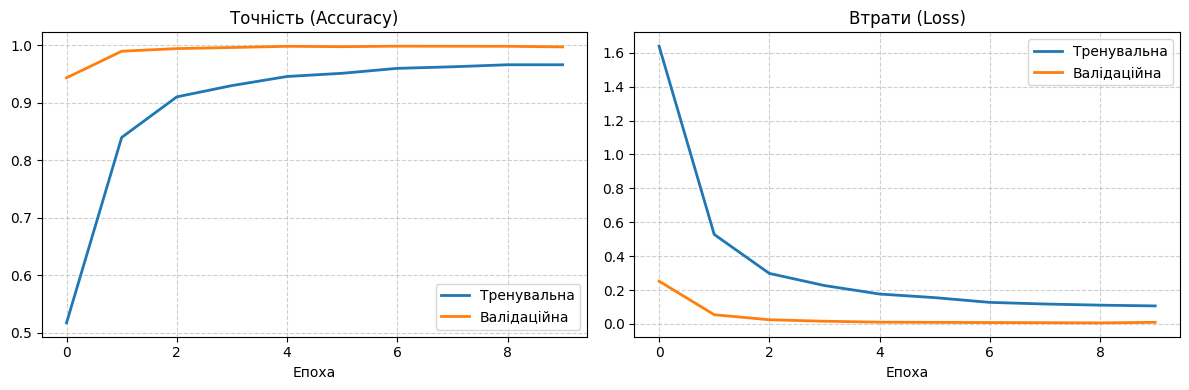

In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))

a1.plot(tr_acc, label='Тренувальна', linewidth=2)
a1.plot(va_acc, label='Валідаційна', linewidth=2)
a1.set_title('Точність (Accuracy)')
a1.set_xlabel('Епоха')
a1.legend()
a1.grid(True, linestyle='--', alpha=0.6)

a2.plot(tr_loss, label='Тренувальна', linewidth=2)
a2.plot(va_loss, label='Валідаційна', linewidth=2)
a2.set_title('Втрати (Loss)')
a2.set_xlabel('Епоха')
a2.legend()
a2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

Точність на тестовому наборі: 98.53%


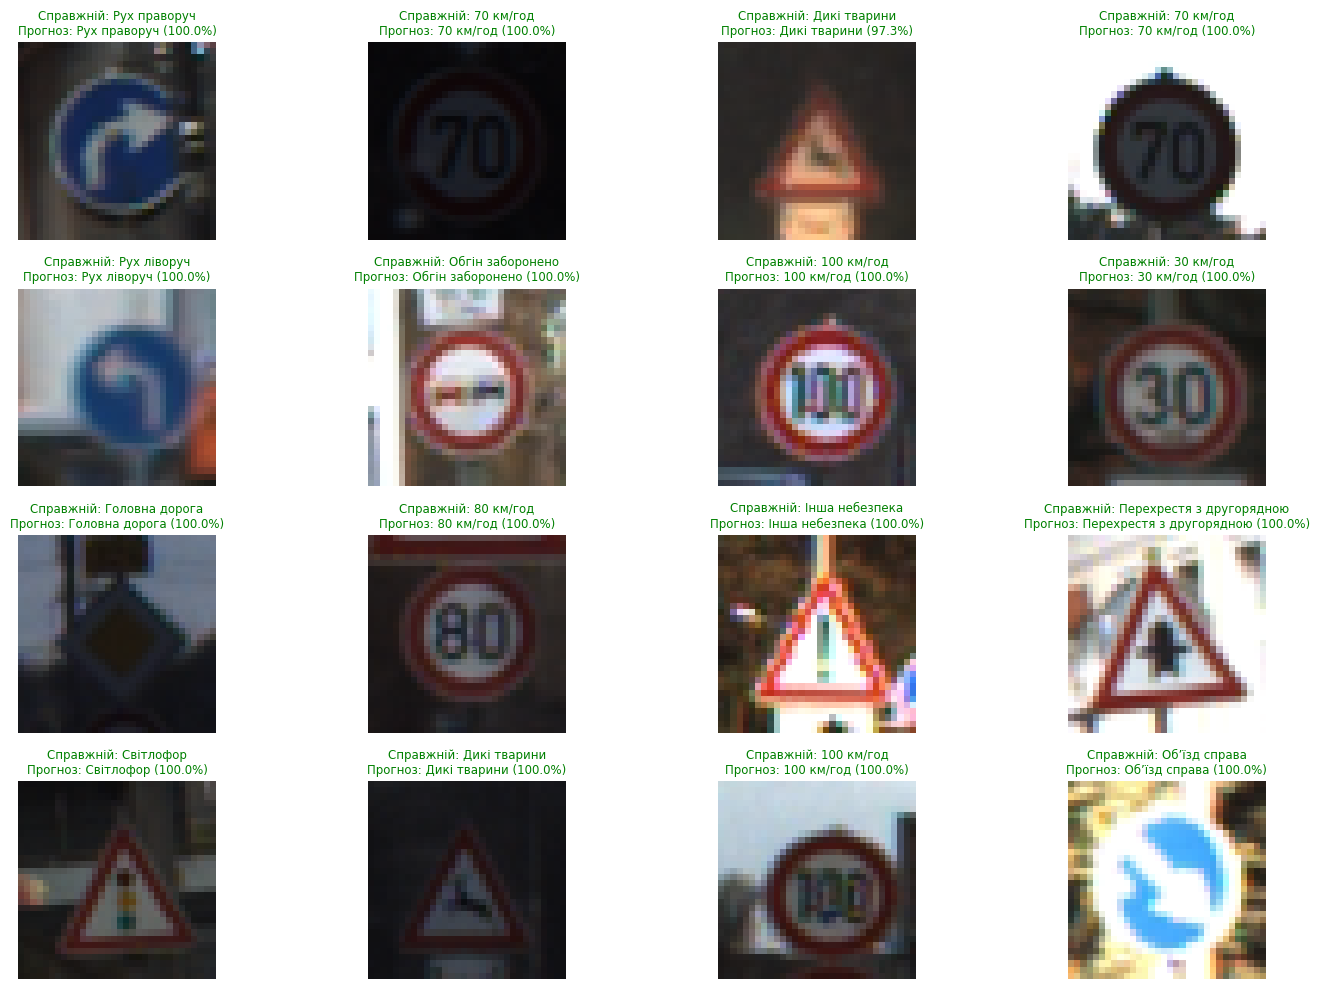

In [9]:
test_df = pd.read_csv(os.path.join(DATA_DIR, 'Test.csv'))
X_te = np.array([
    np.array(Image.open(os.path.join(DATA_DIR, p)).convert('RGB').resize((IMG_SIZE, IMG_SIZE)))
    for p in test_df['Path']
])
y_te = test_df['ClassId'].values

model.eval()
probs_list = []
with torch.no_grad():
    for i in range(0, len(X_te), 256):
        t_in = torch.tensor(X_te[i:i+256].transpose(0, 3, 1, 2), dtype=torch.float32).to(device) / 255.0
        probs_list.append(torch.softmax(model(t_in), dim=1).cpu().numpy())

probs = np.vstack(probs_list)
y_pred = probs.argmax(1)
print(f"Точність на тестовому наборі: {(y_pred == y_te).mean() * 100:.2f}%")

plt.figure(figsize=(15, 10))
for i, idx in enumerate(random.sample(range(len(X_te)), 16)):
    plt.subplot(4, 4, i + 1)
    plt.imshow(X_te[idx])
    t_c, p_c = y_te[idx], y_pred[idx]
    plt.title(
        f"Справжній: {classes[t_c]}\nПрогноз: {classes[p_c]} ({probs[idx][p_c]*100:.1f}%)",
        color='green' if t_c == p_c else 'red',
        fontsize=8.5
    )
    plt.axis('off')

plt.tight_layout()
plt.show()